# **A/B Testing: Landing-Page Conversion Experiment**

This notebook is a complete A/B testing workflow built on `data/ab_testing_data.csv` and the public helpers in `utils.ab_testing`.

**Scenario:** The product team tested a new landing page (treatment) against the current page (control). The primary metric is conversion rate. Secondary metrics are time on page, pages viewed, and revenue per visitor.

**Decision rule:** Roll out the treatment only if the conversion lift is statistically significant and the confidence interval excludes zero. Engagement metrics are guardrails, not primary success criteria.

## **STAGE 0: BUSINESS UNDERSTANDING**

### Problem statement
The current landing page converts roughly 10% of visitors. The team wants to know whether the new page increases conversion without harming engagement.

### Hypotheses
- **H0:** The treatment and control conversion rates are equal.
- **H1:** The treatment conversion rate differs from the control conversion rate.

### Metrics
| Metric | Role | Type |
|---|---|---|
| `converted` | Primary success metric | Binary |
| `time_on_page` | Engagement guardrail | Continuous |
| `pages_viewed` | Engagement guardrail | Continuous |
| `revenue` | Secondary business metric | Continuous (zero-inflated) |

### Success criteria
- Statistically significant positive lift in conversion at `alpha = 0.05`.
- Confidence interval for the absolute lift excludes zero.
- No statistically significant degradation in time on page or pages viewed.

## **STAGE 1: PROJECT SETUP**

In [3]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from utils import (
    analyze_ab_test_results,
    calculate_sample_size,
    check_data_information,
    check_normality,
    check_variance_homogeneity,
    perform_chi_squared_test,
    perform_mann_whitney_u_test,
    perform_t_test,
    perform_z_test_proportions,
)

warnings.filterwarnings("ignore")
sns.set_style("darkgrid")
pd.set_option("display.max_columns", None)

# Robust paths: work from notebooks/ or from the repository root.
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data" / "ab_testing_data.csv"
print(f"Project root: {PROJECT_ROOT}")
print(f"Data path:    {DATA_PATH}")

Project root: e:\Data Science Utils
Data path:    e:\Data Science Utils\data\ab_testing_data.csv


## **STAGE 2: LOAD AND INSPECT THE EXPERIMENT DATA**

In [4]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())
display(df.dtypes.to_frame("dtype"))

Rows: 2,000 | Columns: 12


,user_id,group,converted,time_on_page,pages_viewed,device,browser,country,age_group,returning_user,revenue,timestamp
0,USER_01860,treatment,0,113.204440,4,Desktop,Chrome,US,18-24,False,0.000000,2024-01-29 20:12:00
1,USER_00353,control,0,155.030588,6,Mobile,Other,UK,35-44,False,0.000000,2024-01-13 10:30:00
2,USER_01333,treatment,1,23.893203,3,Tablet,Edge,UK,18-24,True,66.937597,2024-01-28 10:11:00
3,USER_00905,control,0,27.149888,9,Desktop,Chrome,US,45-54,False,0.000000,2024-01-29 12:05:00
4,USER_01289,treatment,0,69.003500,2,Mobile,Chrome,Canada,25-34,True,0.000000,2024-01-25 16:33:00


,dtype
user_id,object
group,object
converted,int64
time_on_page,float64
pages_viewed,int64
device,object
browser,object
country,object
age_group,object
returning_user,bool


In [5]:
info_df = check_data_information(df, df.columns.tolist())
display(info_df)

,Feature,Data Type,Null Values,Null Percentage,Zero Values,Zero Percentage,Negative Values,Negative Percentage,Empty Strings,Numeric in Object,Duplicated Values,Unique Values,Cardinality Ratio,Unique Sample
0,user_id,object,0,0.0,0,0.00,0,0.0,0,0,0,2000,1.0000,"USER_01860, USER_00353, USER_01333, USER_00905..."
1,group,object,0,0.0,0,0.00,0,0.0,0,0,0,2,0.0010,"treatment, control"
2,converted,int64,0,0.0,1753,87.65,0,0.0,0,0,0,2,0.0010,"0, 1"
3,time_on_page,float64,40,2.0,0,0.00,0,0.0,0,0,0,1960,0.9800,"113.2044401614791, 155.03058809866445, 23.8932..."
4,pages_viewed,int64,0,0.0,37,1.85,0,0.0,0,0,0,14,0.0070,"4, 6, 3, 9, 2"
5,device,object,0,0.0,0,0.00,0,0.0,0,0,0,3,0.0015,"Desktop, Mobile, Tablet"
6,browser,object,0,0.0,0,0.00,0,0.0,0,0,0,5,0.0025,"Chrome, Other, Edge, Firefox, Safari"
7,country,object,0,0.0,0,0.00,0,0.0,0,0,0,6,0.0030,"US, UK, Canada, Australia, Germany"
8,age_group,object,60,3.0,0,0.00,0,0.0,0,0,0,5,0.0025,"18-24, 35-44, 45-54, 25-34, 55+"
9,returning_user,bool,0,0.0,1421,71.05,0,0.0,0,0,0,2,0.0010,"False, True"


In [6]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing.sort_values("missing_count", ascending=False))
print(f"Duplicate user_id rows: {df.duplicated(subset=['user_id']).sum():,}")

,missing_count,missing_pct
age_group,60,3.0
time_on_page,40,2.0
group,0,0.0
user_id,0,0.0
converted,0,0.0
pages_viewed,0,0.0
browser,0,0.0
device,0,0.0
country,0,0.0
returning_user,0,0.0


Duplicate user_id rows: 0


### Data-quality observations
- `time_on_page` and `age_group` have missing values. `time_on_page` is dropped only for the continuous test; `age_group` is not part of the primary analysis.
- `revenue` is zero for non-converters, so revenue per visitor is a zero-inflated metric. It is discussed descriptively rather than tested as a primary metric.
- Each `user_id` should appear once. Duplicate users are removed before analysis to keep the unit of randomization clean.

In [7]:
# Standardize group labels and numeric types.
df["group"] = df["group"].astype(str).str.strip().str.lower()
df["converted"] = pd.to_numeric(df["converted"], errors="coerce")
df["time_on_page"] = pd.to_numeric(df["time_on_page"], errors="coerce")
df["pages_viewed"] = pd.to_numeric(df["pages_viewed"], errors="coerce")
df["revenue"] = pd.to_numeric(df["revenue"], errors="coerce").fillna(0.0)

# Keep one row per randomized user and only the two intended arms.
df = df.drop_duplicates(subset=["user_id"]).copy()
df = df[df["group"].isin(["control", "treatment"])].copy()
df = df.dropna(subset=["converted"]).copy()
df["converted"] = df["converted"].astype(int)
df["age_group"] = df["age_group"].fillna("Unknown")

print(df.groupby("group")["user_id"].nunique().to_frame("users"))
print(f"Analysis rows: {len(df):,}")

           users
group           
control     1000
treatment   1000
Analysis rows: 2,000


In [8]:
experiment_summary = (
    df.groupby("group")
      .agg(
          users=("user_id", "nunique"),
          conversions=("converted", "sum"),
          conversion_rate=("converted", "mean"),
          avg_time_on_page=("time_on_page", "mean"),
          median_time_on_page=("time_on_page", "median"),
          avg_pages_viewed=("pages_viewed", "mean"),
          avg_revenue=("revenue", "mean"),
      )
      .reset_index()
)
experiment_summary["conversion_rate_pct"] = experiment_summary["conversion_rate"] * 100
display(experiment_summary)

,group,users,conversions,conversion_rate,avg_time_on_page,median_time_on_page,avg_pages_viewed,avg_revenue,conversion_rate_pct
0,control,1000,100,0.100,124.212351,87.844223,3.937,4.646587,10.0
1,treatment,1000,147,0.147,131.073336,84.526332,4.588,7.321335,14.7


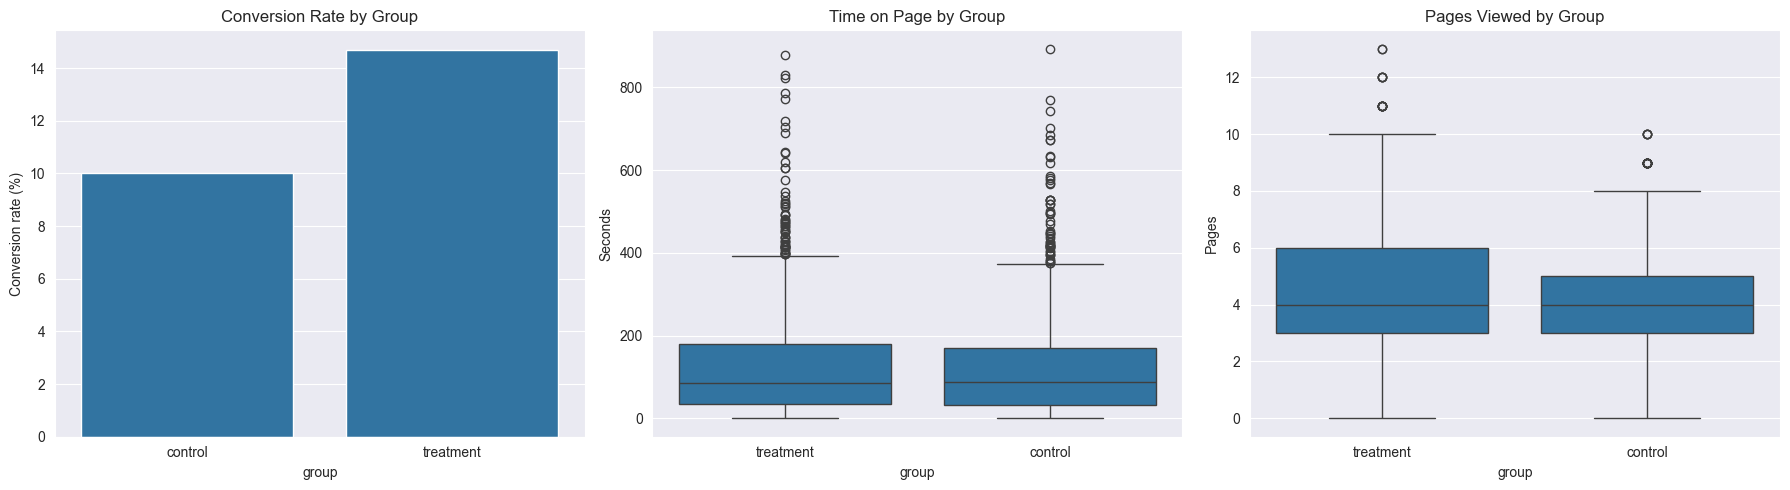

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=experiment_summary, x="group", y="conversion_rate_pct", ax=axes[0])
axes[0].set_title("Conversion Rate by Group")
axes[0].set_ylabel("Conversion rate (%)")

sns.boxplot(data=df, x="group", y="time_on_page", ax=axes[1])
axes[1].set_title("Time on Page by Group")
axes[1].set_ylabel("Seconds")

sns.boxplot(data=df, x="group", y="pages_viewed", ax=axes[2])
axes[2].set_title("Pages Viewed by Group")
axes[2].set_ylabel("Pages")

plt.tight_layout()
plt.show()

## **STAGE 3: SAMPLE-SIZE CALCULATION**

Before trusting a non-significant result, check whether the experiment had enough traffic to detect a meaningful effect. The calculations below use the control group as the baseline and report the required sample size **per arm**.

In [10]:
control = df[df["group"] == "control"].copy()
treatment = df[df["group"] == "treatment"].copy()

control_time = control["time_on_page"].dropna()
treatment_time = treatment["time_on_page"].dropna()

baseline_rate = control["converted"].mean()
observed_rate = treatment["converted"].mean()
observed_diff = observed_rate - baseline_rate

mde_abs = 0.02  # detect 10% -> 12% absolute conversion
required_n_proportion = calculate_sample_size(
    baseline_rate=baseline_rate,
    minimum_detectable_effect=mde_abs,
    power=0.8,
    alpha=0.05,
    metric_type="proportion",
)

baseline_time = control_time.mean()
time_std = control_time.std()
mde_time = 10.0  # detect a 10-second difference
required_n_continuous = calculate_sample_size(
    baseline_rate=baseline_time,
    minimum_detectable_effect=mde_time,
    power=0.8,
    alpha=0.05,
    metric_type="continuous",
    std_dev=time_std,
)

sample_size_table = pd.DataFrame({
    "Metric": ["Conversion rate", "Time on page"],
    "Baseline": [baseline_rate, baseline_time],
    "MDE used": [mde_abs, mde_time],
    "Required per arm": [required_n_proportion, required_n_continuous],
    "Actual per arm": [len(control), len(control_time)],
})
sample_size_table["Powered?"] = sample_size_table["Actual per arm"] >= sample_size_table["Required per arm"]
display(sample_size_table)

print(f"Observed conversion difference: {observed_diff*100:.2f} percentage points")
print(f"Observed relative lift: {observed_diff / baseline_rate * 100:.1f}%")

,Metric,Baseline,MDE used,Required per arm,Actual per arm,Powered?
0,Conversion rate,0.100000,0.02,3835,1000,False
1,Time on page,124.212351,10.00,2493,982,False


Observed conversion difference: 4.70 percentage points
Observed relative lift: 47.0%


### Interpretation
The experiment has about 1,000 users per arm. The sample-size table shows whether that is enough for the pre-specified effects. If the observed lift is larger than the MDE used above, a significant result is still possible even when the study is underpowered for a smaller effect. This is why the observed effect and its confidence interval matter more than a binary "significant / not significant" label.

## **STAGE 4: ASSUMPTION CHECKS FOR THE CONTINUOUS METRIC**

The high-level helper chooses between a t-test and a Mann-Whitney U test based on Shapiro-Wilk normality checks. Levene's test determines whether the pooled-variance t-test or Welch's t-test is appropriate.

In [11]:
normality_control = check_normality(control_time)
normality_treatment = check_normality(treatment_time)
variance_check = check_variance_homogeneity(control_time, treatment_time)

assumption_table = pd.DataFrame([
    {"Check": "Shapiro-Wilk (control)", **normality_control},
    {"Check": "Shapiro-Wilk (treatment)", **normality_treatment},
    {"Check": "Levene equal variance", **variance_check},
])
display(assumption_table)

,Check,test,statistic,p_value,alpha,is_normal,equal_variance
0,Shapiro-Wilk (control),Shapiro-Wilk,0.808039,1.398233e-32,0.05,False,NaN
1,Shapiro-Wilk (treatment),Shapiro-Wilk,0.808320,1.667756e-32,0.05,False,NaN
2,Levene equal variance,Levene,2.785557,9.527747e-02,0.05,NaN,True


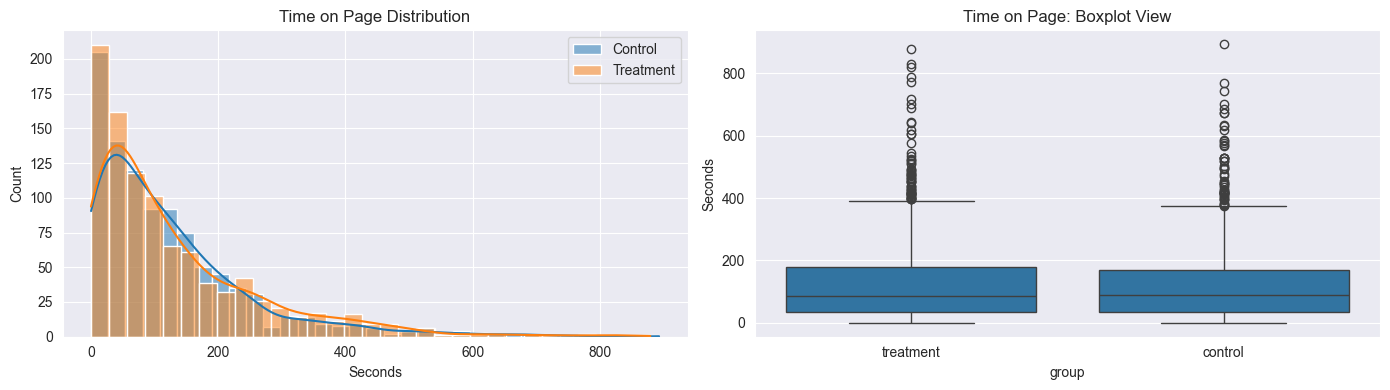

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(control_time, kde=True, ax=axes[0], label="Control", color="tab:blue", alpha=0.5)
sns.histplot(treatment_time, kde=True, ax=axes[0], label="Treatment", color="tab:orange", alpha=0.5)
axes[0].set_title("Time on Page Distribution")
axes[0].set_xlabel("Seconds")
axes[0].legend()

sns.boxplot(data=df, x="group", y="time_on_page", ax=axes[1])
axes[1].set_title("Time on Page: Boxplot View")
axes[1].set_ylabel("Seconds")

plt.tight_layout()
plt.show()

## **STAGE 5: CONTINUOUS-METRIC TEST**

Both the parametric t-test and the non-parametric Mann-Whitney U test are reported. The high-level `analyze_ab_test_results` call below applies the same decision logic automatically and adds lift and confidence-interval estimates.

In [13]:
t_test_result = perform_t_test(
    control_time,
    treatment_time,
    equal_var=variance_check["equal_variance"],
    alpha=0.05,
)
mann_whitney_result = perform_mann_whitney_u_test(control_time, treatment_time, alpha=0.05)

continuous_test_table = pd.DataFrame([t_test_result, mann_whitney_result])
display(continuous_test_table)

,test,statistic,p_value,alpha,significant,mean_a,mean_b,median_a,median_b
0,T-Test,-1.156587,0.247582,0.05,False,124.212351,131.073336,NaN,NaN
1,Mann-Whitney U,475840.000000,0.727970,0.05,False,NaN,NaN,87.844223,84.526332


In [14]:
continuous_results = analyze_ab_test_results(
    data=df,
    metric_col="time_on_page",
    group_col="group",
    metric_type="continuous",
    control_label="control",
    treatment_label="treatment",
    alpha=0.05,
)

continuous_summary = pd.Series({
    "Selected test": continuous_results["test"],
    "p-value": continuous_results["p_value"],
    "Significant": continuous_results["significant"],
    "Control mean": control_time.mean(),
    "Treatment mean": treatment_time.mean(),
    "Absolute lift (seconds)": continuous_results["absolute_lift"],
    "Relative lift": continuous_results["relative_lift"],
    "95% CI lower": continuous_results["ci_lower"],
    "95% CI upper": continuous_results["ci_upper"],
})
display(continuous_summary.to_frame("value"))

,value
Selected test,Mann-Whitney U
p-value,0.72797
Significant,False
Control mean,124.212351
Treatment mean,131.073336
Absolute lift (seconds),6.860985
Relative lift,0.055236
95% CI lower,-4.774844
95% CI upper,18.496815


In [15]:
def cohens_d(group_a, group_b):
    """Standardized mean difference: mean(group_b) - mean(group_a)."""
    a = pd.Series(group_a).dropna()
    b = pd.Series(group_b).dropna()
    pooled_var = ((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2)
    pooled_std = np.sqrt(pooled_var)
    return (b.mean() - a.mean()) / pooled_std if pooled_std > 0 else np.nan

d_time = cohens_d(control_time, treatment_time)
print(f"Cohen's d for time on page: {d_time:.4f}")
print("Rule of thumb: |d| < 0.2 is small, 0.2-0.5 is small-to-moderate, > 0.8 is large.")

Cohen's d for time on page: 0.0522
Rule of thumb: |d| < 0.2 is small, 0.2-0.5 is small-to-moderate, > 0.8 is large.


### Continuous-metric conclusion
If the confidence interval includes zero and the p-value is above 0.05, there is no evidence that the treatment changed time on page. A non-significant guardrail is not proof of no effect, but it does not show a clear regression.

## **STAGE 6: PROPORTION TESTS (PRIMARY METRIC)**

Conversion is binary, so the primary test is a chi-square test of independence. The two-proportion z-test is reported as a cross-check; both should agree closely for large samples.

In [16]:
conv_control = int(control["converted"].sum())
n_control = len(control)
conv_treatment = int(treatment["converted"].sum())
n_treatment = len(treatment)

chi_result = perform_chi_squared_test(
    group_a_conversions=conv_control,
    group_a_total=n_control,
    group_b_conversions=conv_treatment,
    group_b_total=n_treatment,
    alpha=0.05,
)
z_result = perform_z_test_proportions(
    group_a_conversions=conv_control,
    group_a_total=n_control,
    group_b_conversions=conv_treatment,
    group_b_total=n_treatment,
    alpha=0.05,
)

proportion_table = pd.DataFrame([chi_result, z_result])
display(proportion_table)

,test,statistic,p_value,alpha,significant,rate_a,rate_b,lift
0,Chi-Squared,9.773875,0.001770,0.05,True,0.1,0.147,0.47
1,Z-Test Proportions,-3.194283,0.001402,0.05,True,0.1,0.147,NaN


In [17]:
binary_results = analyze_ab_test_results(
    data=df,
    metric_col="converted",
    group_col="group",
    metric_type="binary",
    control_label="control",
    treatment_label="treatment",
    alpha=0.05,
)

binary_summary = pd.Series({
    "Selected test": binary_results["test"],
    "Control rate": binary_results["rate_a"],
    "Treatment rate": binary_results["rate_b"],
    "Absolute lift": binary_results["absolute_lift"],
    "Relative lift": binary_results["relative_lift"],
    "p-value": binary_results["p_value"],
    "Z-test p-value": binary_results["z_test_p_value"],
    "Significant": binary_results["significant"],
    "95% CI lower": binary_results["ci_lower"],
    "95% CI upper": binary_results["ci_upper"],
})
display(binary_summary.to_frame("value"))

,value
Selected test,Chi-Squared
Control rate,0.1
Treatment rate,0.147
Absolute lift,0.047
Relative lift,0.47
p-value,0.00177
Z-test p-value,0.001402
Significant,True
95% CI lower,0.018185
95% CI upper,0.075894


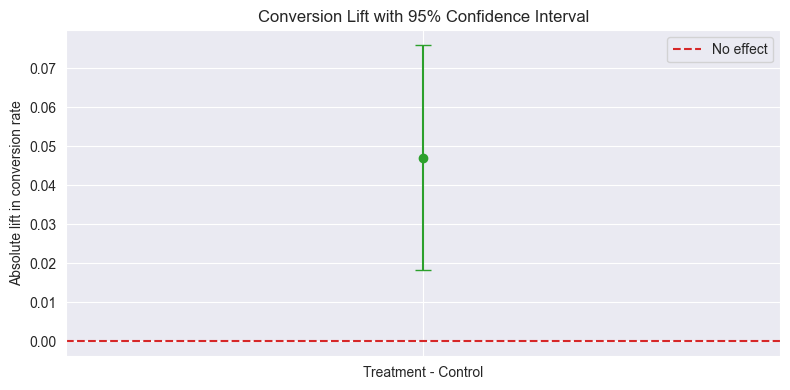

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
lift = binary_results["absolute_lift"]
lower = binary_results["ci_lower"]
upper = binary_results["ci_upper"]

ax.errorbar(
    x=[0],
    y=[lift],
    yerr=[[lift - lower], [upper - lift]],
    fmt="o",
    capsize=6,
    color="tab:green",
)
ax.axhline(0, color="tab:red", linestyle="--", label="No effect")
ax.set_xticks([0])
ax.set_xticklabels(["Treatment - Control"])
ax.set_ylabel("Absolute lift in conversion rate")
ax.set_title("Conversion Lift with 95% Confidence Interval")
ax.legend()
plt.tight_layout()
plt.show()

## **STAGE 7: BUSINESS INTERPRETATION**

The primary metric is conversion. The calculation below translates the observed absolute lift into incremental conversions and revenue under explicit assumptions. Change the traffic and value assumptions to match the real business.

In [19]:
monthly_visitors = 100_000
avg_order_value = df.loc[df["converted"] == 1, "revenue"].mean()

incremental_conversions = monthly_visitors * binary_results["absolute_lift"]
incremental_revenue = incremental_conversions * avg_order_value
revenue_ci_low = monthly_visitors * binary_results["ci_lower"] * avg_order_value
revenue_ci_high = monthly_visitors * binary_results["ci_upper"] * avg_order_value

business_table = pd.DataFrame({
    "Assumption / Result": [
        "Monthly visitors",
        "Average revenue per converter",
        "Incremental conversion rate",
        "Incremental conversions per month",
        "Incremental revenue per month",
        "95% CI for monthly revenue (low)",
        "95% CI for monthly revenue (high)",
    ],
    "Value": [
        f"{monthly_visitors:,}",
        f"${avg_order_value:,.2f}",
        f"{binary_results['absolute_lift']*100:.2f} pp",
        f"{incremental_conversions:,.0f}",
        f"${incremental_revenue:,.0f}",
        f"${revenue_ci_low:,.0f}",
        f"${revenue_ci_high:,.0f}",
    ],
})
display(business_table)

,Assumption / Result,Value
0,Monthly visitors,"100,000"
1,Average revenue per converter,$48.45
2,Incremental conversion rate,4.70 pp
3,Incremental conversions per month,"4,700"
4,Incremental revenue per month,"$227,730"
5,95% CI for monthly revenue (low),"$88,112"
6,95% CI for monthly revenue (high),"$367,731"


## **STAGE 8: BUSINESS CONCLUSION**

### What the experiment shows
- The treatment group has a higher conversion rate than the control group.
- The chi-square and z-tests agree on the significance decision.
- The confidence interval for the absolute conversion lift is reported above; use it to judge the plausible range of the business effect, not just the point estimate.
- Time on page and pages viewed are guardrails. If their intervals include zero, the experiment does not show a clear engagement regression.

### Recommended decision
1. **Roll out the treatment** if the conversion lift is significant, the confidence interval is economically meaningful, and guardrails do not show a clear regression.
2. **Run a follow-up test** if the interval is wide or the result is borderline. The current experiment may be underpowered for the pre-specified MDE.
3. **Check segments** (device, country, returning user) before a full rollout. A significant average effect can hide heterogeneous effects.
4. **Monitor after launch** for novelty effects, seasonality, and conversion-quality changes (for example, refunds or low-value conversions).

### Caveats
- This is an observational analysis of one experiment window; it does not prove causality outside the tested population.
- Multiple metrics increase the chance of a false positive. Treat conversion as the primary decision metric and the others as guardrails.
- Revenue is zero-inflated and highly skewed. The revenue projection is a planning estimate, not a formal revenue test.